# Experiment 1: compare approaches
This notebook reads only completed portable analysis summaries and histogram CSV files. It never opens raw recordings, models, or simulator code. Loading ranges and motion selections are compared separately.

In [1]:
import os, json, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Find this checkout whether Jupyter starts in the repository or notebooks directory.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "exp1_analysis.py").exists())
sys.path.insert(0, str(REPO / "notebooks"))
import exp1_analysis as exp1
# Refresh helper changes even when this Jupyter kernel was already running.
import importlib
exp1 = importlib.reload(exp1)

from b1z1_paper_names import DISPLAY_NAMES, LATEX_METHOD_NAMES
# Paper labels differ from implementation ablation numbers; task IDs stay unchanged.
CONFIG = {
    # New batch summaries use task-named folders; exclude older aliases such as exp1/pact.
    "summary_roots": [str(p) for p in sorted((REPO / "analysis/exp1").glob("b1z1_*")) if p.is_dir()],
    "output_dir": str(REPO / "analysis/exp1_comparison/in"),
    "method_order": [
        "b1z1_unifp_original", "b1z1_ppo_pos",
        "b1z1_pact_ab6_position_film", "b1z1_pact_ab7_position_full",
        "b1z1_pact_ab8_coupled_film", "b1z1_pact_ab4_coupled_none",
        "b1z1_pact_ab5_coupled_concat", "b1z1_pact_ab9_representation",
        "b1z1_pact_ab10_actor", "b1z1_pact"],
    "display_names": dict(DISPLAY_NAMES),
    "latex_method_names": dict(LATEX_METHOD_NAMES),  # Requires manuscript macro definitions.
    "focused_methods": ["b1z1_pact", "b1z1_unifp_original", "b1z1_ppo_pos"],
    "load_range": "in",  # Analyze "out" separately.
    "motion": "combined",  # "stationary", "locomotion", or explicitly exported "combined".
    "motion_modes_table": True,  # Separate stationary/locomotion table; does not change motion above.
    "motion_modes_condition": "combined-disturbance",  # Uses load_range and focused_methods above.
    "response_table": True,
    "optional_metrics": [],  # e.g. ["torso_angular_acceleration_rms", "ee_linear_acceleration_rms"]
    "additional_plots": ["step", "ecdf", "box"],  # Set [] to export only the original histogram.
}
if os.environ.get("EXP1_COMPARE_CONFIG"):
    CONFIG.update(json.loads(Path(os.environ["EXP1_COMPARE_CONFIG"]).read_text()))
CONFIG


{'summary_roots': ['/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab10_actor',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab4_coupled_none',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab5_coupled_concat',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab6_position_film',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab7_position_full',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab8_coupled_film',
  '/home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1/b1z1_pact_ab9_representation',
  '/home/oyoungquist/Res

## Validation and tables
The disturbance-response table also reports **EE recovered [%]** (EE-position tolerance only) and **Velocity recovered [%]** (planar velocity and yaw-rate tolerances). Each uses the same eligible events, response window, contiguous dwell and whole-trial failure censoring as joint recovery. Rerun summarization for all approaches to populate these new metrics; comparison never estimates them from joint recovery.
Protocols, units, histogram bins/frames and seed coverage must agree. Duplicate method summaries are rejected. Missing results display as an em dash. Each cell reports **mean ± sample SD across evaluation seeds**; tracking/failure/recovery fractions are displayed as percentages.

CSV and LaTeX tables are exported. The main table uses text width; focused tables use column width (`graphicx` and `booktabs` required). Times New Roman is used for figures if installed, with a serif fallback.

Immediately after the main table, `motion_modes_table` compares stationary manipulation and locomotion with manipulation for the focused methods: EE position error [m], planar velocity error [m/s], yaw-rate error [rad/s], joint S_track [%], velocity-only S_track [%], manipulation-only S_track [%], and failure rate [%]. Velocity-only requires both planar velocity and yaw-rate tolerances; manipulation-only requires the EE-position tolerance. All scores use the full prescribed horizon with zero credit after failure. Rerun the summarization notebook for every approach to calculate the new scores from transitions; they cannot be inferred from joint S_track. This comparison reads only portable-summary strata for `motion_modes_condition`, without changing global motion selection. `motion_modes.csv` retains numeric means, sample SDs and counts (fractions converted once to percent); `motion_modes.tex` is a single-column grouped table. Missing results are never replaced with combined-motion results.

main


nominal                                                \
              EE [m] Velocity [m/s]    Yaw [rad/s]    Tracking [%]   
UniFP  0.030 ± 0.000  0.038 ± 0.001  0.064 ± 0.001  98.946 ± 0.028   
Pos    0.025 ± 0.000  0.044 ± 0.000  0.066 ± 0.000  98.849 ± 0.019   
A1     0.073 ± 0.000  0.042 ± 0.000  0.065 ± 0.000  83.129 ± 0.222   
A2     0.038 ± 0.000  0.057 ± 0.001  0.070 ± 0.001  97.165 ± 0.114   
A3     0.044 ± 0.000  0.045 ± 0.000  0.067 ± 0.000  98.259 ± 0.011   
A4     0.032 ± 0.000  0.042 ± 0.001  0.068 ± 0.000  98.776 ± 0.034   
A5     0.043 ± 0.000  0.043 ± 0.000  0.068 ± 0.000  98.721 ± 0.019   
A6     0.031 ± 0.000  0.045 ± 0.000  0.066 ± 0.000  98.895 ± 0.038   
A7     0.025 ± 0.000  0.050 ± 0.001  0.092 ± 0.001  96.720 ± 0.280   
PILOT  0.022 ± 0.000  0.052 ± 0.001  0.065 ± 0.000  98.871 ± 0.026   

                     ee-disturbance                                \
         Failure [%]         EE [m] Velocity [m/s]    Yaw [rad/s]   
UniFP  0.000 ± 0.000  0.072 ± 0.002  0.057 ± 0.000  0.087 ± 0.000   
Pos    0.000 ± 0.000  0.064 ± 0.001  0.056 ± 0.001  0.080 ± 0.001   
A1     0.000 ± 0.000  0.097 ± 0.002  0.060 ± 0.000  0.089 ± 0.002   
A2     0.000 ± 0.000  0.096 ± 0.003  0.076 ± 0.001  0.118 ± 0.004   
A3     0.000 ± 0.000  0.071 ± 0.002  0.060 ± 0.001  0.081 ± 0.002   
A4     0.000 ± 0.000  0.061 ± 0.001  0.056 ± 0.000  0.086 ± 0.002   
A5     0.000 ± 0.000  0.068 ± 0.001  0.060 ± 0.000  0.083 ± 0.001   
A6     0.000 ± 0.000  0.057 ± 0.000  0.056 ± 0.000  0.086 ± 0.001   
A7     0.000 ± 0.000  0.055 ± 0.001  0.072 ± 0.001  0.129 ± 0.002   
PILOT  0.000 ± 0.000  0.054 ± 0.001  0.067 ± 0.000  0.105 ± 0.001   

                                     combined-disturbance                 \
         Tracking [%]    Failure [%]               EE [m] Velocity [m/s]   
UniFP  76.949 ± 1.704  7.667 ± 3.055        0.072 ± 0.001  0.063 ± 0.001   
Pos    79.120 ± 1.428  0.667 ± 0.577        0.064 ± 0.002  0.064 ± 0.001   
A1     63.239 ± 1.864  1.000 ± 1.000        0.097 ± 0.002  0.072 ± 0.002   
A2     61.685 ± 1.596  1.000 ± 1.000        0.096 ± 0.003  0.086 ± 0.002   
A3     79.945 ± 0.962  0.000 ± 0.000        0.071 ± 0.002  0.070 ± 0.002   
A4     84.112 ± 0.901  0.000 ± 0.000        0.062 ± 0.001  0.067 ± 0.001   
A5     82.903 ± 0.376  0.000 ± 0.000        0.068 ± 0.001  0.070 ± 0.001   
A6     85.593 ± 0.505  0.333 ± 0.577        0.057 ± 0.000  0.068 ± 0.000   
A7     78.500 ± 0.192  0.000 ± 0.000        0.056 ± 0.001  0.085 ± 0.001   
PILOT  82.445 ± 0.576  0.333 ± 0.577        0.054 ± 0.000  0.081 ± 0.002   

                                                     
         Yaw [rad/s]    Tracking [%]    Failure [%]  
UniFP  0.091 ± 0.001  76.818 ± 1.079  6.000 ± 2.646  
Pos    0.086 ± 0.000  77.163 ± 1.297  1.667 ± 0.577  
A1     0.097 ± 0.003  61.068 ± 1.602  1.000 ± 1.000  
A2     0.126 ± 0.004  59.572 ± 1.206  2.000 ± 1.000  
A3     0.089 ± 0.001  77.499 ± 1.138  0.333 ± 0.577  
A4     0.093 ± 0.003  81.073 ± 1.064  0.000 ± 0.000  
A5     0.090 ± 0.001  80.458 ± 0.793  0.000 ± 0.000  
A6     0.091 ± 0.001  82.584 ± 0.128  1.000 ± 0.000  
A7     0.136 ± 0.002  74.679 ± 0.539  0.000 ± 0.000  
PILOT  0.111 ± 0.002  78.721 ± 1.420  0.333 ± 0.577

motion_modes


Mean EE position error [m] ↓  \
Motion                       Method                                
Stationary manipulation      PILOT                 0.056 ± 0.002   
                             UniFP                 0.068 ± 0.003   
                             Pos                   0.058 ± 0.004   
Locomotion with manipulation PILOT                 0.052 ± 0.002   
                             UniFP                 0.075 ± 0.001   
                             Pos                   0.070 ± 0.003   

                                    Planar velocity error [m/s] ↓  \
Motion                       Method                                 
Stationary manipulation      PILOT                  0.047 ± 0.001   
                             UniFP                  0.044 ± 0.001   
                             Pos                    0.035 ± 0.001   
Locomotion with manipulation PILOT                  0.115 ± 0.003   
                             UniFP                  0.083 ± 0.002   
                             Pos                    0.093 ± 0.001   

                                    Yaw-rate error [rad/s] ↓   S_track [%] ↑  \
Motion                       Method                                            
Stationary manipulation      PILOT             0.079 ± 0.001  83.976 ± 1.221   
                             UniFP             0.071 ± 0.002  77.690 ± 1.281   
                             Pos               0.062 ± 0.001  82.956 ± 2.778   
Locomotion with manipulation PILOT             0.143 ± 0.003  73.466 ± 2.208   
                             UniFP             0.110 ± 0.004  75.946 ± 0.882   
                             Pos               0.111 ± 0.002  71.370 ± 0.185   

                                    Velocity S_track [%] ↑  \
Motion                       Method                          
Stationary manipulation      PILOT          96.622 ± 0.236   
                             UniFP          93.364 ± 0.492   
                             Pos            97.917 ± 0.742   
Locomotion with manipulation PILOT          78.715 ± 2.166   
                             UniFP          88.479 ± 2.168   
                             Pos            88.865 ± 0.469   

                                    Manipulation S_track [%] ↑  \
Motion                       Method                              
Stationary manipulation      PILOT              84.652 ± 1.244   
                             UniFP              77.930 ± 1.248   
                             Pos                83.024 ± 2.790   
Locomotion with manipulation PILOT              87.988 ± 1.025   
                             UniFP              78.816 ± 1.143   
                             Pos                75.929 ± 0.554   

                                    Failure rate [%] ↓  
Motion                       Method                     
Stationary manipulation      PILOT       0.000 ± 0.000  
                             UniFP       6.000 ± 0.000  
                             Pos         1.333 ± 1.155  
Locomotion with manipulation PILOT       0.667 ± 1.155  
                             UniFP       6.000 ± 5.292  
                             Pos         2.000 ± 0.000

physical_limits


Saturation [%]   Position [%]   Velocity [%]
Method Condition                                                        
PILOT  nominal               0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       ee-disturbance        0.030 ± 0.004  0.088 ± 0.019  0.000 ± 0.000
       combined-disturbance  0.030 ± 0.005  0.089 ± 0.008  0.000 ± 0.000
UniFP  nominal               0.018 ± 0.001  0.000 ± 0.000  0.000 ± 0.000
       ee-disturbance        0.030 ± 0.001  0.096 ± 0.022  0.000 ± 0.000
       combined-disturbance  0.031 ± 0.002  0.095 ± 0.016  0.000 ± 0.000
Pos    nominal               0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       ee-disturbance        0.005 ± 0.001  0.108 ± 0.026  0.000 ± 0.000
       combined-disturbance  0.007 ± 0.007  0.102 ± 0.026  0.000 ± 0.000

disturbance_response


Peak EE [m]   Recovery [s]   Recovered [%]  \
Method Condition                                                            
PILOT  ee-disturbance        0.148 ± 0.000  0.394 ± 0.028  74.667 ± 1.453   
       combined-disturbance  0.149 ± 0.001  0.399 ± 0.045  68.111 ± 2.341   
UniFP  ee-disturbance        0.277 ± 0.001  0.679 ± 0.011  75.333 ± 2.848   
       combined-disturbance  0.278 ± 0.002  0.699 ± 0.006  75.333 ± 1.202   
Pos    ee-disturbance        0.160 ± 0.006  0.318 ± 0.009  75.444 ± 1.347   
       combined-disturbance  0.160 ± 0.004  0.322 ± 0.008  71.111 ± 1.540   

                            EE recovered [%] Velocity recovered [%]  
Method Condition                                                     
PILOT  ee-disturbance         82.222 ± 1.711         87.778 ± 0.770  
       combined-disturbance   81.000 ± 1.202         81.000 ± 2.404  
UniFP  ee-disturbance         77.111 ± 2.694         88.667 ± 2.333  
       combined-disturbance   77.778 ± 1.503         87.778 ± 1.953  
Pos    ee-disturbance         76.889 ± 1.018         97.111 ± 0.839  
       combined-disturbance   75.000 ± 0.882         90.556 ± 1.388

b1z1_pact: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
b1z1_pact_ab10_actor: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
b1z1_pact_ab4_coupled_none: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
b1z1_pact_ab5_coupled_concat: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
b1z1_pact_ab6_position_film: Evaluator-source hash validation disabled by ignore_evaluator_source_hash=True; evaluation-code equivalence has not been verified. Original hashes are retained in provenance.
b1z1_

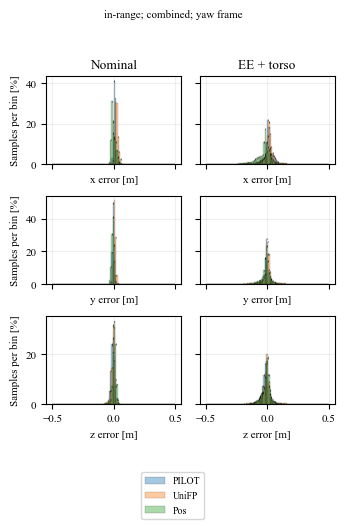

In [2]:
tables, figure, diagnostics = exp1.compare(CONFIG)
for name, table in tables.items():
    print(name)
    display(table)
print("\n".join(diagnostics) or "Compatible complete comparison.")


## Signed EE-error distributions
Overlaid histogram bars show equal-seed mean percentage of samples per bin; error bars show sample SD across seeds. These are bin probabilities, not density curves. Rows are x/y/z; columns are nominal and combined disturbances. All methods share bins and axes. Tails are preserved in the histogram exports and `ee_distribution_data.csv`; probabilities are **not** renormalized to hide tails. Vector PDF and PNG are exported alongside tables.

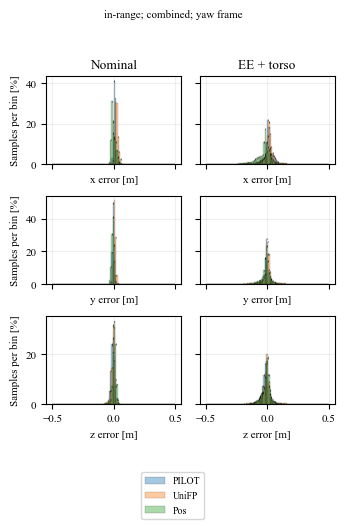

step


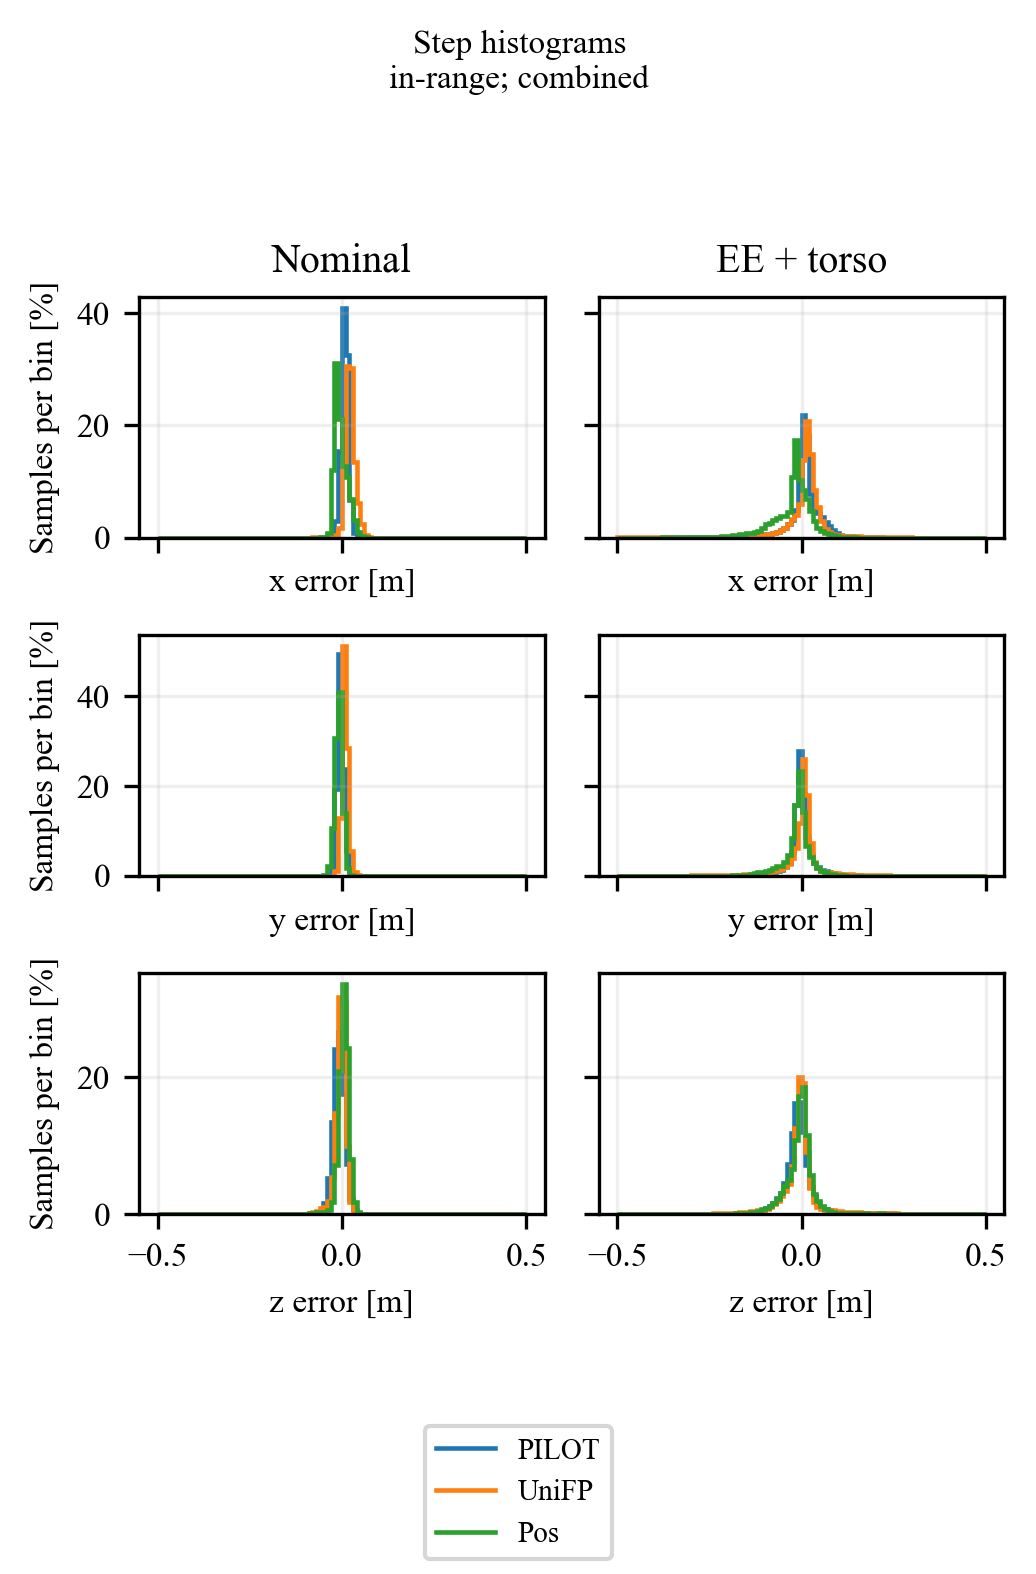

ecdf


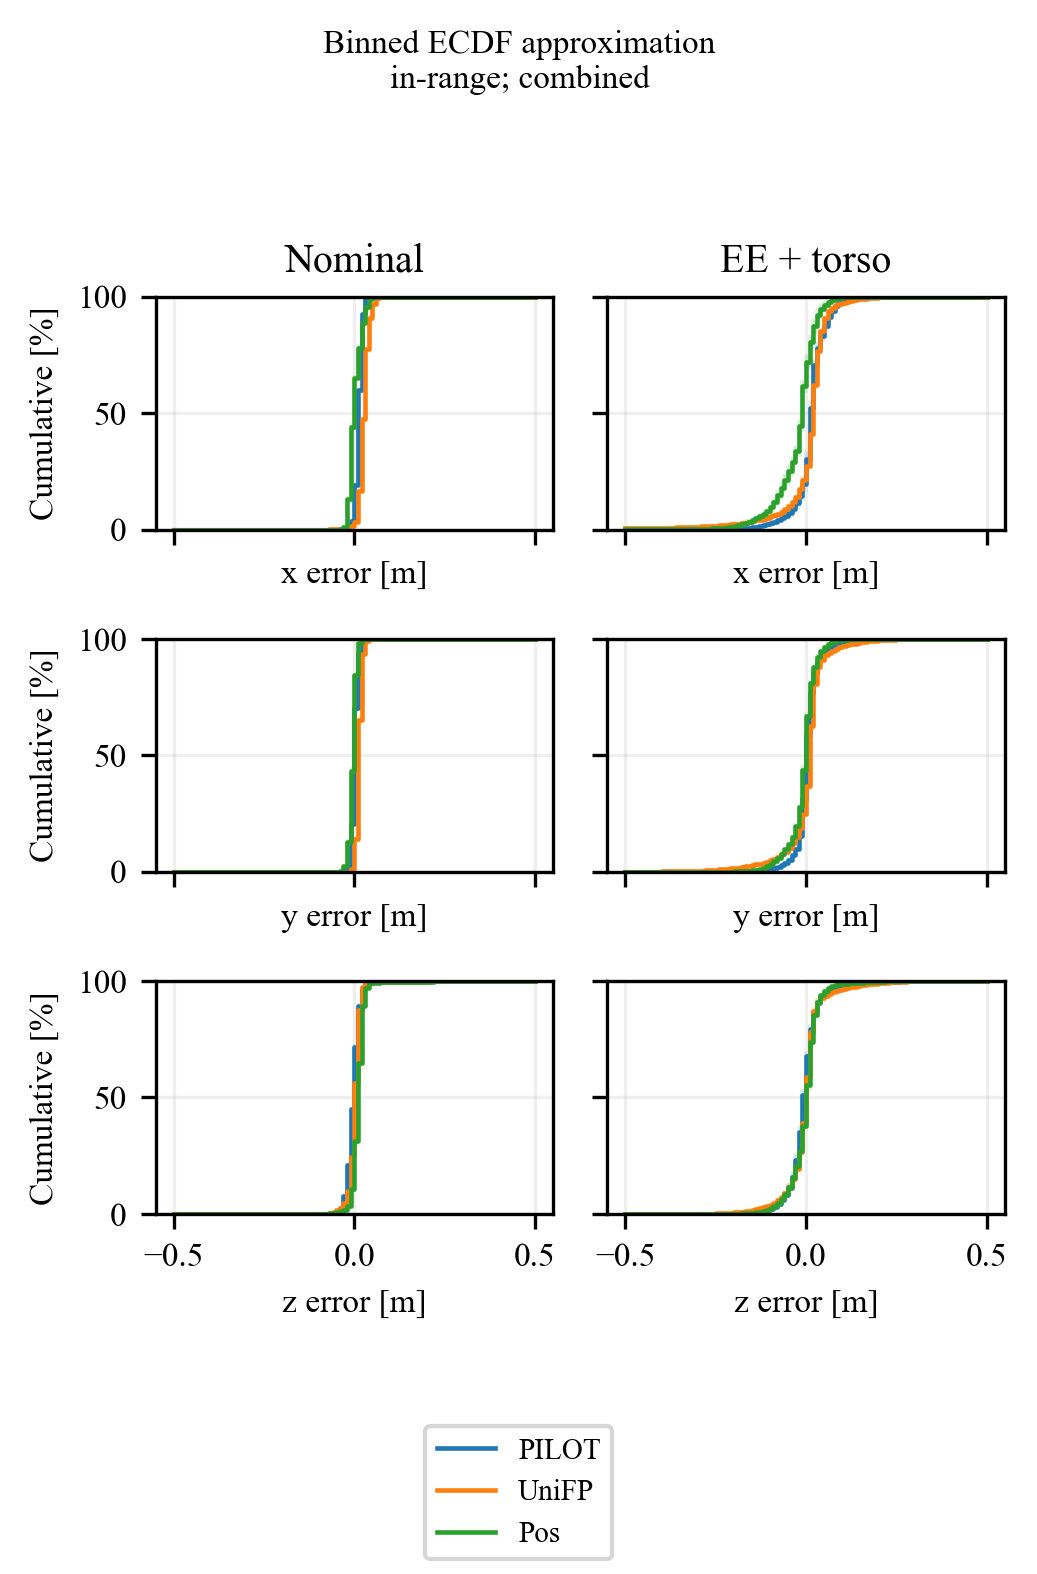

box


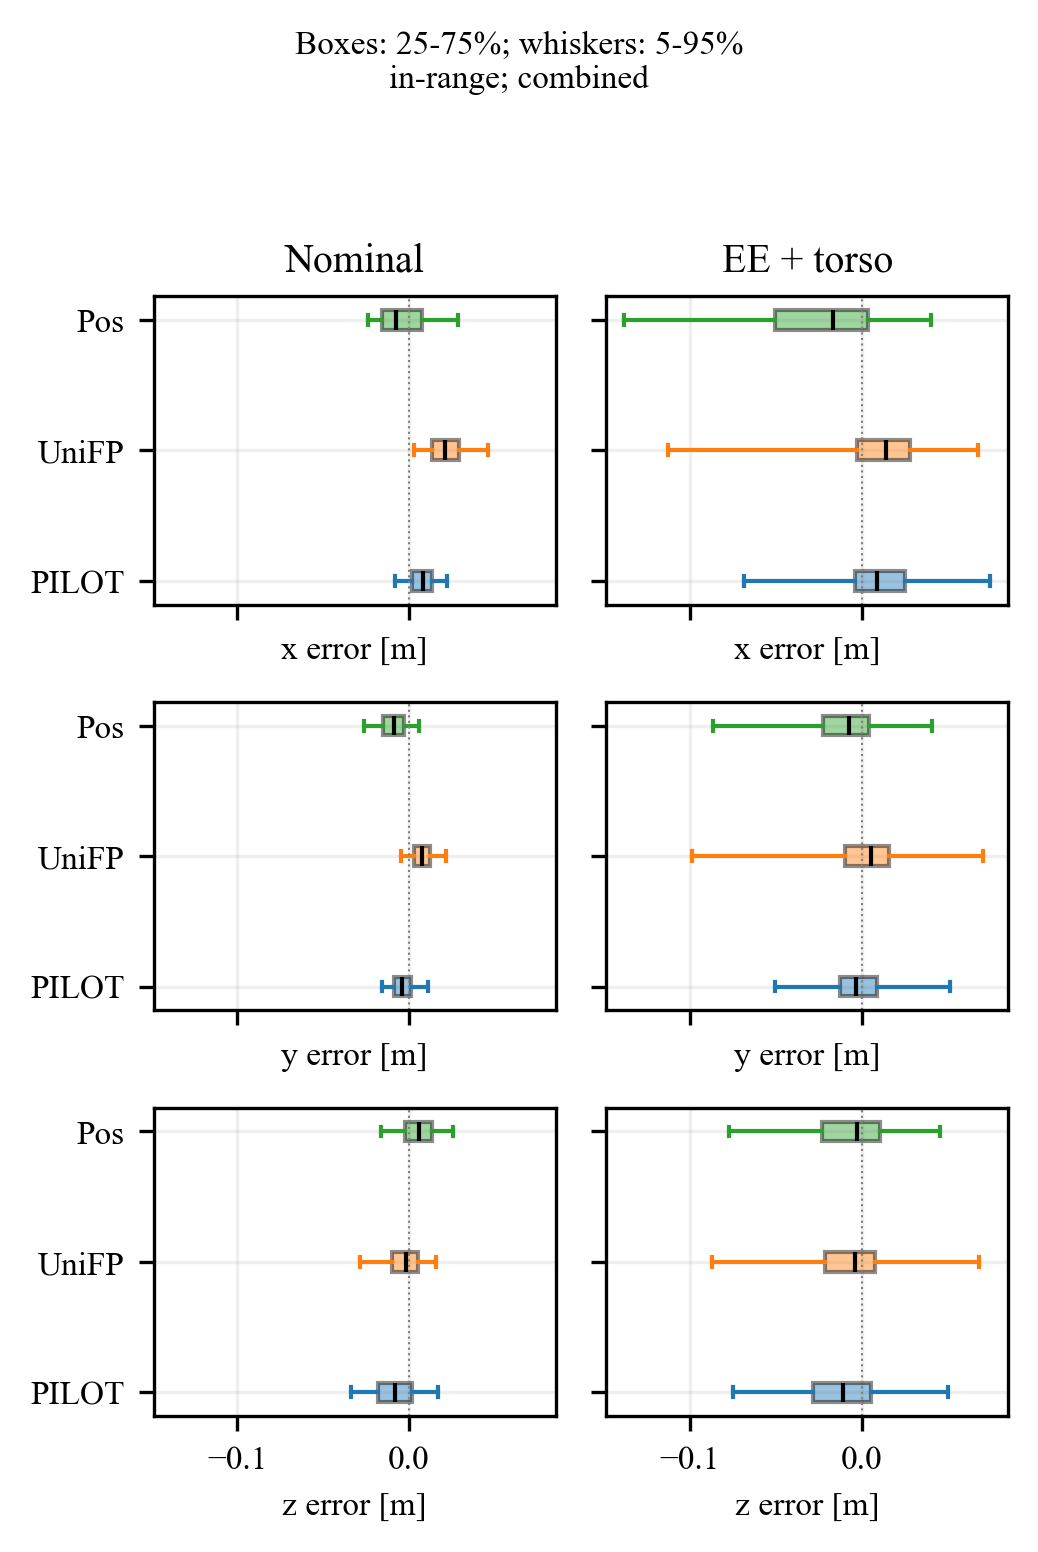

Exported: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp1_comparison/in


In [3]:
display(figure)
# ECDF is binned; exact equal-seed box statistics require rerunning the summarization notebook.
# Boxes show median and 25-75% spread; whiskers are 5-95%, not Tukey fences or confidence intervals.
from IPython.display import Image
for kind in CONFIG.get("additional_plots", ["step", "ecdf", "box"]):
    print(kind)
    display(Image(filename=str(Path(CONFIG["output_dir"]) / f"ee_{kind}.png")))
print("Exported:", CONFIG["output_dir"])
